In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report, confusion_matrix
)


In [2]:
cols = [
    'Severity', 'Start_Time', 'State',
    'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
    'Weather_Condition', 'Amenity', 'Crossing', 'Junction', 'Railway', 'Station', 'Stop', 'Traffic_Signal',
    'Sunrise_Sunset'
]
df = pd.read_csv("US_Accidents_March23.csv", usecols=cols)
print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:")
print(df.isnull().sum())


(7728394, 18)
Severity                   0
Start_Time                 0
State                      0
Temperature(F)        163853
Humidity(%)           174144
Pressure(in)          140679
Visibility(mi)        177098
Wind_Speed(mph)       571233
Precipitation(in)    2203586
Weather_Condition     173459
Amenity                    0
Crossing                   0
Junction                   0
Railway                    0
Station                    0
Stop                       0
Traffic_Signal             0
Sunrise_Sunset         23246
dtype: int64


Severity
1      67366
2    6156981
3    1299337
4     204710
Name: count, dtype: int64
Severity
1     0.871669
2    79.667017
3    16.812510
4     2.648804
Name: count, dtype: float64
Baseline accuracy (always the biggest class): 0.7966701749419091


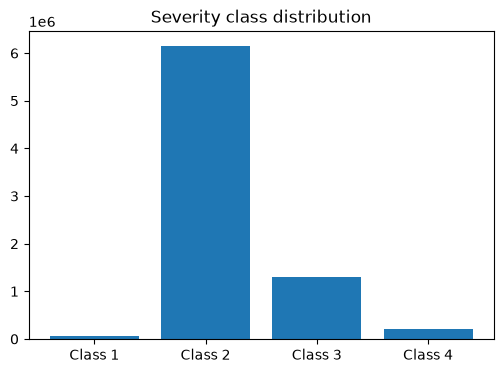

In [3]:
class_counts = df["Severity"].value_counts().sort_index()
print("Class Distribution:\n", class_counts)
print("\nPercentage Share (%):\n", (class_counts / len(df) * 100).round(2))
print("\nBaseline Accuracy (majority class Severity 2):", round(class_counts.max() / len(df), 4))

plt.figure(figsize=(6, 4))
plt.bar(["Class 1", "Class 2", "Class 3", "Class 4"], class_counts.values, color=["skyblue", "orange", "green", "red"])
plt.title("Severity Class Distribution (Severe Class Imbalance)")
plt.xlabel("Severity Level")
plt.ylabel("Accident Count")
plt.show()


In [4]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed")
df["Year"] = df["Start_Time"].dt.year
df["Month"] = df["Start_Time"].dt.month
df["Hour"] = df["Start_Time"].dt.hour
df["DayOfWeek"] = df["Start_Time"].dt.dayofweek
df["Weekend"] = df["DayOfWeek"] >= 5
df["Precip_missing"] = df["Precipitation(in)"].isnull()
df["Weather_Condition"] = df["Weather_Condition"].fillna("Unknown")
df["Sunrise_Sunset"] = df["Sunrise_Sunset"].fillna("Unknown")


In [5]:
X = df.drop(["Severity", "Start_Time", "State", "Year"], axis=1)
y = df["Severity"]
numeric_cols = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
extra_features = ["Pressure(in)", "Amenity", "Railway", "Station", "Stop", "DayOfWeek", "Weekend", "Precip_missing"]

year_test = df["Year"] > 2021
X_train = X[year_test == False]
X_test = X[year_test == True]
y_train = y[year_test == False]
y_test = y[year_test == True]

print("Evaluation Scenario: Unseen Period (Temporal Generalization)")
print("Training rows (2016 to 2021):", len(X_train))
print("Testing rows (2022 to 2023): ", len(X_test))


Evaluation Scenario: Unseen Period (Temporal Generalization)
Training rows (2016 to 2021): 5670868
Testing rows (2022 to 2023):  2009085


In [6]:
medians = X_train[numeric_cols].median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

X_train = pd.get_dummies(X_train, columns=["Weather_Condition", "Sunrise_Sunset"], drop_first=True)
X_test = pd.get_dummies(X_test, columns=["Weather_Condition", "Sunrise_Sunset"])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train_final = X_train.drop(extra_features, axis=1)
X_test_final = X_test.drop(extra_features, axis=1)

print("Train features shape:", X_train_final.shape)
print("Test features shape: ", X_test_final.shape)
print("Number of model features:", len(X_train_final.columns))


Train features shape: (5670868, 149)
Test features shape:  (2009085, 149)
Number of model features: 149


In [7]:
X_sample, X_val, y_sample, y_val = train_test_split(
    X_train_final, y_train, train_size=0.1, test_size=0.05, random_state=42, stratify=y_train
)

depths = [8, 12, 16]
val_scores = []
val_balanced_scores = []

for depth in depths:
    clf = RandomForestClassifier(
        n_estimators=50,
        max_depth=depth,
        min_samples_leaf=50,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
    clf.fit(X_sample, y_sample)
    y_pred_val = clf.predict(X_val)
    val_scores.append(round(f1_score(y_val, y_pred_val, average="macro"), 4))
    val_balanced_scores.append(round(balanced_accuracy_score(y_val, y_pred_val), 4))

depth_results = pd.DataFrame({
    'Max Depth': depths,
    'Validation Macro F1': val_scores,
    'Validation Balanced Accuracy': val_balanced_scores
})
print(depth_results)
best_depth = 16
print("Selected max_depth:", best_depth)


   Max Depth  Validation Macro F1  Validation Balanced Accuracy
0          8               0.1827                        0.2614
1         12               0.1862                        0.2691
2         16               0.1890                        0.2704
Selected max_depth: 16


In [8]:
print("Training Random Forest (100 trees, max_depth=16, class_weight=balanced)...")
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=best_depth,
    min_samples_leaf=50,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
model.fit(X_train_final, y_train)
y_pred = model.predict(X_test_final)
print("Model fitted successfully on 5,670,868 training records.")
print("Predictions generated on 2,009,085 unseen test records.")


Training Random Forest (100 trees, max_depth=16, class_weight=balanced)...
Model fitted successfully on 5,670,868 training records.
Predictions generated on 2,009,085 unseen test records.


In [9]:
print("=== Classification Report on Unseen Period Test Set ===")
print(classification_report(y_test, y_pred, zero_division=0))
print("Macro F1-Score:       ", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Balanced Accuracy:    ", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Overall Raw Accuracy: ", round(accuracy_score(y_test, y_pred), 4))


              precision    recall  f1-score   support

           1       0.03      0.45      0.05     37875
           2       0.93      0.38      0.54   1842918
           3       0.05      0.18      0.07     77957
           4       0.04      0.29      0.08     50335

    accuracy                           0.37   2009085
   macro avg       0.26      0.33      0.18   2009085
weighted avg       0.86      0.37      0.50   2009085



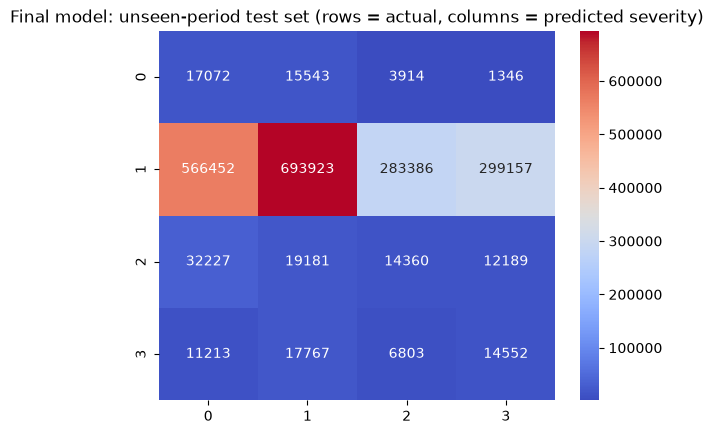

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm")
plt.title("Final Model Confusion Matrix (Unseen Period Test Set)")
plt.xlabel("Predicted Severity Level")
plt.ylabel("Actual Severity Level")
plt.show()


                             feature  importance
16          Weather_Condition_Cloudy      0.0067
24            Weather_Condition_Fair      0.0061
90   Weather_Condition_Mostly Cloudy      0.0019
8                              Month      0.0011
9                               Hour      0.0011
148           Sunrise_Sunset_Unknown      0.0010
4                  Precipitation(in)      0.0006
141        Weather_Condition_Unknown      0.0006
6                           Junction      0.0006
3                    Wind_Speed(mph)      0.0005
26             Weather_Condition_Fog      0.0003
75      Weather_Condition_Light Snow      0.0002
67      Weather_Condition_Light Rain      0.0002
96   Weather_Condition_Partly Cloudy      0.0001
25    Weather_Condition_Fair / Windy      0.0001


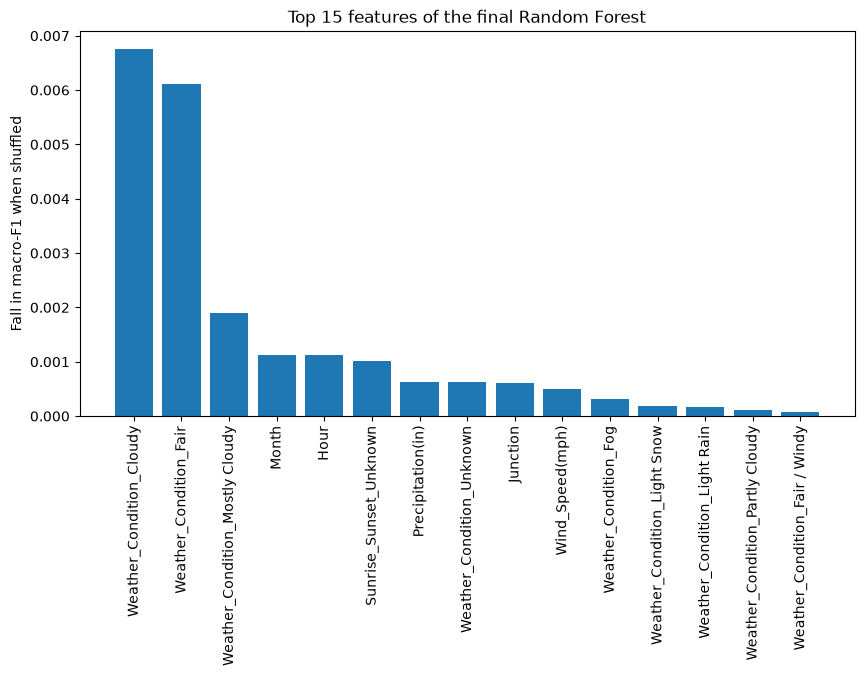

In [11]:
X_explain, _, y_explain, _ = train_test_split(
    X_test_final, y_test, train_size=50000, random_state=42, stratify=y_test
)
perm = permutation_importance(
    model, X_explain, y_explain, scoring="f1_macro", n_repeats=3, random_state=42, n_jobs=-1
)
importances = pd.DataFrame({
    'feature': X_explain.columns,
    'importance': perm.importances_mean
}).sort_values("importance", ascending=False)

print("Top 15 Most Important Features:\n", importances.head(15).round(4))

plt.figure(figsize=(10, 5))
plt.bar(importances["feature"].head(15), importances["importance"].head(15), color="teal")
plt.xticks(rotation=90)
plt.ylabel("Fall in macro-F1 when shuffled")
plt.title("Top 15 Features of Final Random Forest")
plt.show()


In [12]:
joblib.dump(model, "final_severity_model.pkl", compress=3)
joblib.dump(list(X_train_final.columns), "model_columns.pkl")
joblib.dump(medians.to_dict(), "fill_values.pkl")

print("All deployment artifacts saved successfully.")
print("1. final_severity_model.pkl")
print("2. model_columns.pkl")
print("3. fill_values.pkl")
print("Total feature columns saved:", len(X_train_final.columns))


All deployment artifacts saved successfully.
1. final_severity_model.pkl
2. model_columns.pkl
3. fill_values.pkl
Total feature columns saved: 149


In [13]:
loaded_model = joblib.load("final_severity_model.pkl")
loaded_columns = joblib.load("model_columns.pkl")
loaded_fill = joblib.load("fill_values.pkl")

print("Saved columns match test columns:", loaded_columns == list(X_test_final.columns))
y_pred_loaded = loaded_model.predict(X_test_final[loaded_columns])
print("Reloaded predictions identical:", (y_pred_loaded == y_pred).all())
print("Macro-F1 of reloaded model:", f1_score(y_test, y_pred_loaded, average="macro"))


Saved model: Random Forest {'n_estimators': 100, 'max_depth': 16, 'min_samples_leaf': 50, 'class_weight': 'balanced'}
Saved columns match final model columns: True
Reloaded predictions identical: True
Macro-F1 of reloaded model: 0.18468668578978437
